# Topic 9 - Machine Learning (Part 2)

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:

1. Understand machine learning algorithms - support vector machines (SVM), decision trees, random forests, kMeans, etc.
2. Apply machine learning techniques to real-world data
3. Evaluate machine learning solutions

---

---

**Recap: What We've Learnt So Far...**
1. Naive Bayes is an example of a simple **generator** classifier
2. SVMs are an example of a **discriminative** classifier
3. Both methods have strengths and weaknesses

---

In [3]:
# UserWarning: "KMeans is known to have a memory leak on Windows with MKL, when there 
# are less chunks than available threads. You can avoid it by setting the environment 
# variable OMP_NUM_THREADS=2.

# For the solution to work, we need to run this code at the beginning of the notebook.
import os
os.environ["OMP_NUM_THREADS"] = "1"

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 9.3 Decision Trees and Random Forests </h2>
</div>

### 9.3.1 Decision Trees

Another type of **discriminative** classifier:
- Ask questions to 'zero in' on a class
- A bit like '20 questions'

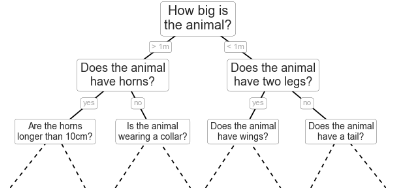

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.08-random-forests.html

Many benefits:
- Easy to **understand** and **interpret**
- Classification process is **transparent**
- Handles **numeric** and **categorical** data (and missing data)
- Can be used for both **classification** and **regression**

Some drawbacks:
- How do you decide **which questions** to ask?
- Easy to **overfit**
- Hard to find an **optimal** decision tree


Consider a set of 4 classes

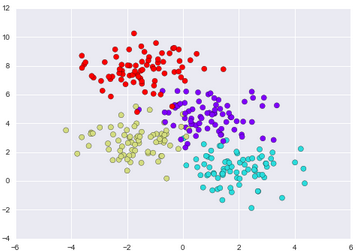

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.08-random-forests.html

The proccess:
- Try **partitioning** the data by each of the attributes
- Choose the partition with the **lowest entropy**
- Add a **decision node** for that attribute and **repeat** on each subset

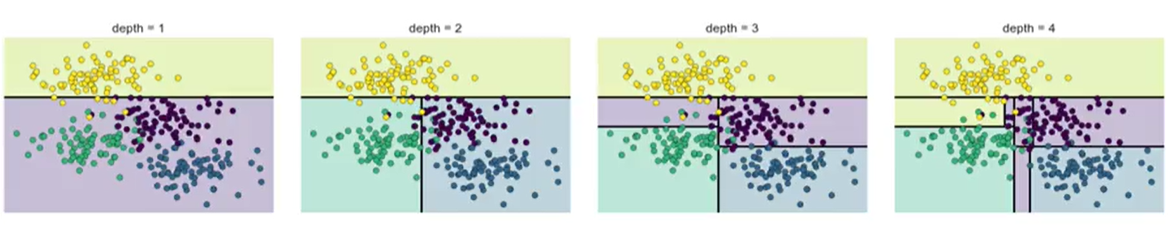

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.08-random-forests.html


In [4]:
# standard imports
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

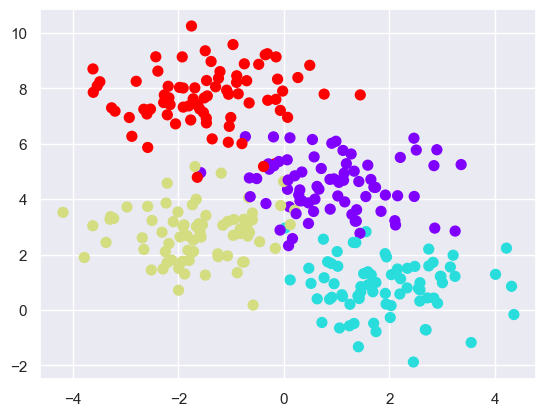

In [5]:
# create some data with 4 'classes'
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=300, centers=4,
                  random_state=0, cluster_std=1.0)
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='rainbow');

In [6]:
X

array([[ 2.45830537e-02,  2.96215652e+00],
       [-1.52392631e+00,  7.12573205e+00],
       [ 1.27450825e+00,  5.63017322e+00],
       [-8.65523345e-01,  7.80121774e+00],
       [ 7.48740670e-01,  2.55579434e+00],
       [ 4.35918422e+00, -1.62352163e-01],
       [-1.99576820e+00,  7.16440976e-01],
       [ 1.70536064e+00,  4.43277024e+00],
       [ 4.90616903e-01,  8.82985441e+00],
       [-3.52995502e-01,  9.21042408e+00],
       [-1.83601846e+00,  2.68441560e+00],
       [-3.61784268e+00,  8.69951232e+00],
       [ 1.42013331e+00,  4.63746165e+00],
       [-2.88089030e+00,  6.26769229e+00],
       [ 1.05505217e+00, -6.47107437e-01],
       [ 1.05472929e-01,  3.72493766e+00],
       [ 1.13121750e+00,  4.68194985e+00],
       [ 2.91209813e+00,  2.46638067e-01],
       [-7.60240832e-01,  3.27417508e+00],
       [-7.79715679e-01,  1.72893731e+00],
       [ 3.15492712e+00,  1.55292739e+00],
       [ 1.59167155e+00,  1.37914513e+00],
       [ 5.73093132e-01,  5.52623240e+00],
       [-2.

In [7]:
# instantiate a decision tree classifier
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier().fit(X,y)
# tree = DecisionTreeClassifier(max_depth=3).fit(X,y)  #set maximum depth of tree

In [8]:
# quick utility function to help us visualize the output of the classifier
def visualize_classifier(model, X, y, ax=None, cmap='rainbow'):
    ax = ax or plt.gca()

    # plot the training points
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=cmap,
               zorder=3)
    ax.axis('tight')
    ax.axis('off')
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # fit the estimator
    model.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(*xlim, num=200),
    np.linspace(*ylim, num=200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # create a color plot with the results
    n_classes = len(np.unique(y))
    contours = ax.contourf(xx, yy, Z, alpha=0.3,
                       levels=np.arange(n_classes + 1) - 0.5,
                       cmap=cmap,
                       vmin=y.min(), vmax=y.max(),
                       zorder=1)
    ax.set(xlim=xlim, ylim=ylim)

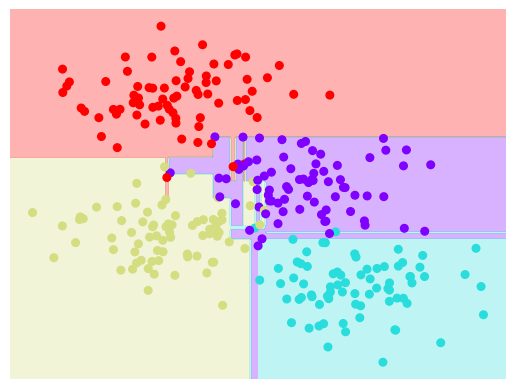

In [9]:
# now we can visualise the classification
visualize_classifier(DecisionTreeClassifier(), X, y)

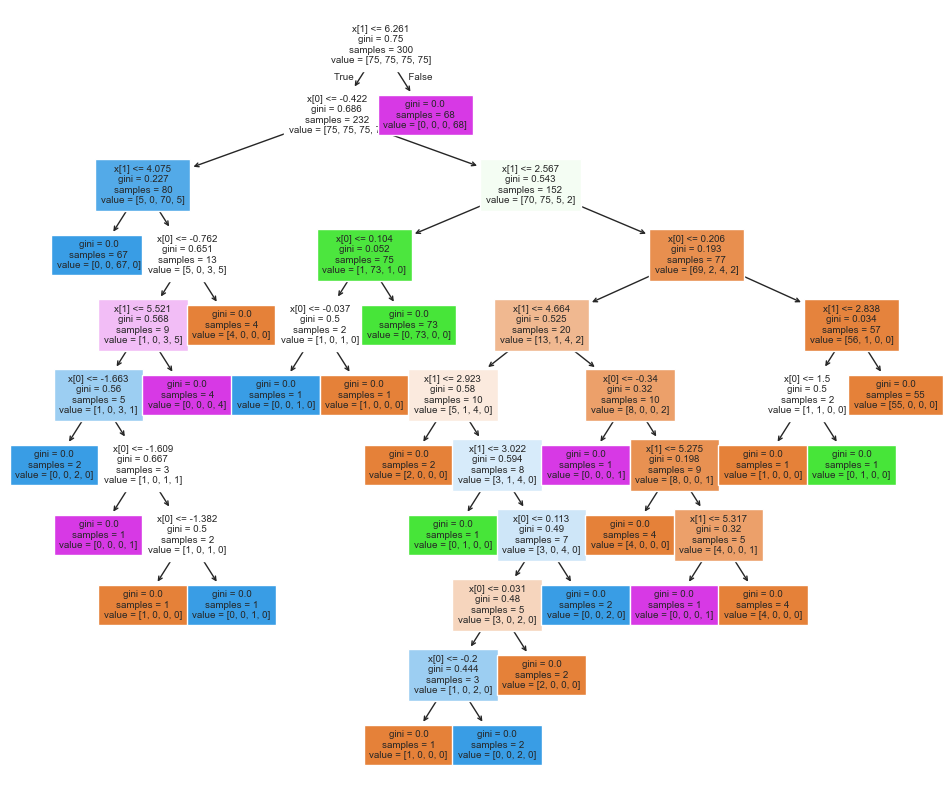

In [10]:
# Additional - Plot the decision tree
from sklearn.tree import plot_tree
plt.figure(figsize=(12,10))
plot_tree(tree, filled=True, fontsize=7)
plt.show()

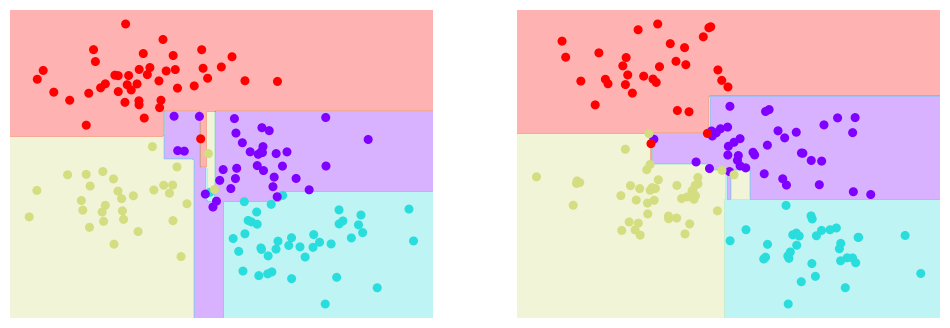

In [11]:
# some oddly shaped regions - overfitting? 
# especially if we go too deep: fitting on sample not population.
# can examine using models trained on 2 subsets
fig, ax = plt.subplots(1, 2, figsize=(12,4))
visualize_classifier(DecisionTreeClassifier(), X[::2], y[::2], ax=ax[0])
visualize_classifier(DecisionTreeClassifier(), X[1::2], y[1::2], ax=ax[1])

In [ ]:
# inconsistencies appear where there is uncertainty
# could we combine multiple trees?

---

**Summary:**
1. Decision trees are a type of **discriminative** classifier
2. They have many strengths, e.g., **transparency**, **explainability**, etc.
3. But they do have some drawbacks, e.g., **overfitting**

---

### 9.3.2 Random Forests

Using **two** decision trees is **better than one**... How about **many** decision trees?

**Ensemble** methods
- **Bagging**: use **multiple parallel estimators** to return an **average result**
- An ensemble of decision trees is called a **random forest**

Scikit-learn offers a **BaggingClassifier** and a **RandomForestClassifier**


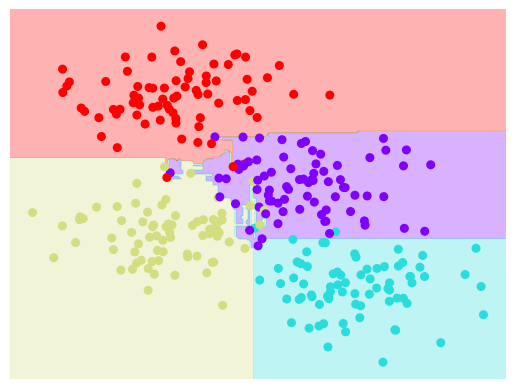

In [12]:
# combine multiple overfitting estimators into an ensemble
# average gives better classification outcome
# e.g., each of 100 estimators uses random 80% of data
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

tree = DecisionTreeClassifier()
bag = BaggingClassifier(tree, n_estimators=100, max_samples=0.8,
                        random_state=1)

bag.fit(X, y)
visualize_classifier(bag, X, y)

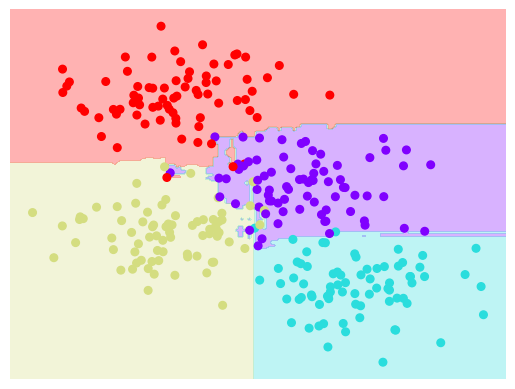

In [13]:
# but decision trees (DT) are more effective with more principled randomization strategy,
# e.g., how splits are chosen, which features to use, etc.
# -> use an optimized ensemble of randomized decision trees
from sklearn.ensemble import RandomForestClassifier

# we just select number of estimators = 100
model = RandomForestClassifier(n_estimators=100, random_state=0)
visualize_classifier(model, X, y);

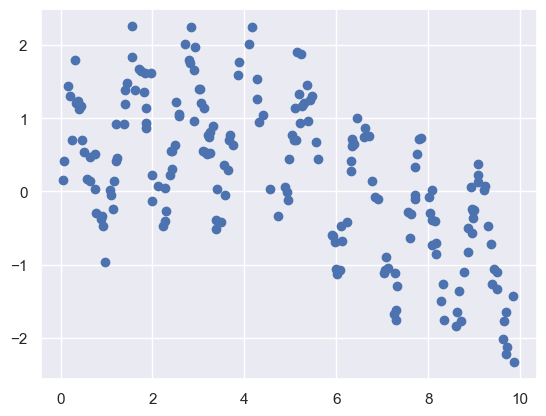

In [14]:
# overall model is much closer to our intuitions of how data should be partitioned

# random forests can also be used for regression (continuous variables)
# let's create some data based on a combination of 2 sinusoidal functions

rng = np.random.RandomState(42)
x = 10 * rng.rand(200)

def model(x, sigma=0.3):
    fast_oscillation = np.sin(5 * x)
    slow_oscillation = np.sin(0.5 * x)
    noise = sigma * rng.randn(len(x))

    return slow_oscillation + fast_oscillation + noise

y = model(x)
# plt.errorbar(x, y, yerr=0.3, fmt='o');
plt.scatter(x, y);

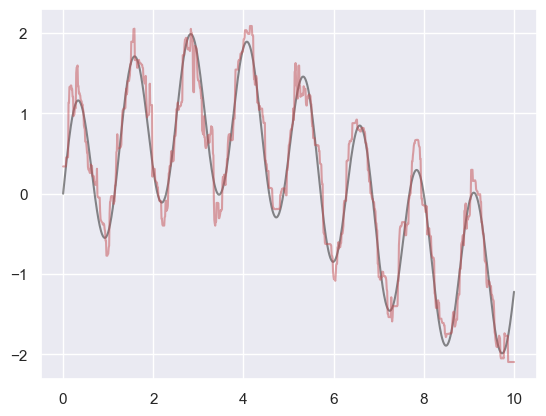

In [15]:
# now find the best fit curve

from sklearn.ensemble import RandomForestRegressor
forest = RandomForestRegressor(200)  # n_estimators=200 (number of trees)
forest.fit(x[:, None], y)

xfit = np.linspace(0, 10, 1000)  # 1000 points
yfit = forest.predict(xfit[:, None])  # predict y values for each
ytrue = model(xfit, sigma=0)  # apply original function with zero noise

plt.plot(xfit, ytrue, '-k', alpha=0.5)
plt.plot(xfit, yfit, '-r', alpha=0.5);
# plt.errorbar(x, y, 0.3, fmt='o', alpha=0.5)


In [16]:
# Random forest (RF) is flexible enough to model complex continuous functions

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 9.4 Clustering </h2>
</div>

---

**Recap: What We've Learnt So Far...**
1. Machine learning techniques can be **supervised** or **unsupervised**
2. ... and also **semi-supervised** or **reinforcement** learning
3. Unsupervised learning includes **clustering** and **dimensionality reduction**

---

### 9.4.1 k-Means Clustering

Seeks to learn an **optimal division** or labeling of a data set
- k-Means is one such popular algorithm
- Searches for a predetermined number of clusters within an unlabelled dataset

An **optimal clustering** is one where:
- A **cluster centre** is arithmetic mean of all its members
- Each point is **closer to its own cluster centre** than to any others
  

In [17]:
# begin with standard imports
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()  # for plot styling

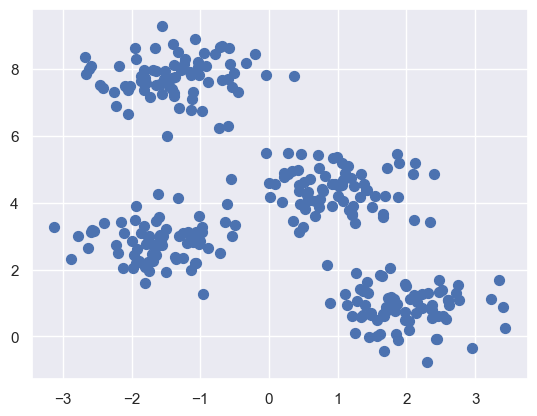

In [18]:
# generate some 'clusterable' data, composed of 4 blobs in 2D space
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.6, random_state=0)
plt.scatter(X[:,0], X[:,1], s=50);

In [19]:
# we can see the cluster centres by eye
# but can scikit-learn do so?
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

In [20]:
# could compare true labels with kmeans output.. which is a lot of data points
print(y_true)
print(y_kmeans)

# Note: k-Means cluster labels (y_kmeans) may not match true labels (y_true)
# because k-Means is unsupervised and does not use true class information.

[1 3 0 3 1 1 2 0 3 3 2 3 0 3 1 0 0 1 2 2 1 1 0 2 2 0 1 0 2 0 3 3 0 3 3 3 3
 3 2 1 0 2 0 0 2 2 3 2 3 1 2 1 3 1 1 2 3 2 3 1 3 0 3 2 2 2 3 1 3 2 0 2 3 2
 2 3 2 0 1 3 1 0 1 1 3 0 1 0 3 3 0 1 3 2 2 0 1 1 0 2 3 1 3 1 0 1 1 0 3 0 2
 2 1 3 1 0 3 1 1 0 2 1 2 1 1 1 1 2 1 2 3 2 2 1 3 2 2 3 0 3 3 2 0 2 0 2 3 0
 3 3 3 0 3 0 1 2 3 2 1 0 3 0 0 1 0 2 2 0 1 0 0 3 1 0 2 3 1 1 0 2 1 0 2 2 0
 0 0 0 1 3 0 2 0 0 2 2 2 0 2 3 0 2 1 2 0 3 2 3 0 3 0 2 0 0 3 2 2 1 1 0 3 1
 1 2 1 2 0 3 3 0 0 3 0 1 2 0 1 2 3 2 1 0 1 3 3 3 3 2 2 3 0 2 1 0 2 2 2 1 1
 3 0 0 2 1 3 2 0 3 0 1 1 2 2 0 1 1 1 0 3 3 1 1 0 1 1 1 3 2 3 0 1 1 3 3 3 1
 1 0 3 2]
[0 2 3 2 0 0 1 3 2 2 1 2 3 2 0 3 3 0 1 1 0 0 3 1 1 3 0 3 1 3 2 2 3 2 2 2 2
 2 1 0 3 1 3 3 1 1 2 1 2 0 1 0 2 0 0 1 2 1 2 0 2 3 2 1 1 1 2 0 2 1 3 1 2 1
 1 2 1 3 0 2 0 3 0 0 2 3 0 3 2 2 3 0 2 1 1 3 0 0 3 1 2 0 2 0 3 0 0 3 2 3 1
 1 0 2 0 3 2 0 0 3 1 0 1 0 0 0 0 1 0 1 2 1 1 0 2 1 1 2 3 2 2 1 3 1 3 1 2 3
 2 2 2 3 2 3 0 1 2 1 0 3 2 3 3 0 3 1 1 3 0 3 3 2 0 3 1 2 0 0 3 1 0 3 1 1 3
 3 3 3 0 2 3 1 

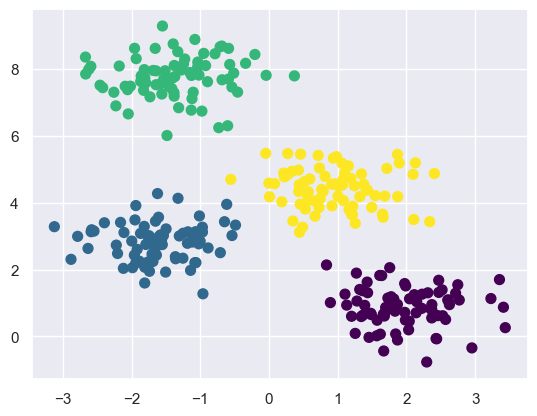

In [21]:
# but it's easier to visualize
plt.scatter(X[:,0], X[:,1], c=y_kmeans, s=50, cmap='viridis');

# and also show the cluster centres:
# centers = kmeans.cluster_centers_
# plt.scatter(centers[:,0], centers[:,1], c='black', s=200, alpha=0.5);

In [ ]:
# cluster assignments seem highly plausible - how come so fast?
# all possible combinations is exponential in number of points

---

**Summary:**
1. Clustering is a type of **unsupervised** learning
2. **k-Means** is a popular clustering algorithm
3. k-Means tries to find a **predetermined number** of clusters

---

### 9.4.2 Expectation Maximization

Finding an **optimal division** of a data set is difficult
- Number of **possible combinations** is **exponential** in number of points

The **Expectation Maximization (EM) algorithm**:
1. Assign some random cluster centres
2. Repeat until converged:
    - E-Step: Assign points to nearest cluster centre
    - M-Step: Set the cluster centres to the mean

Each repetition will result in a **better estimate**

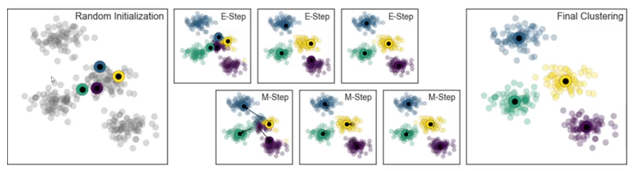

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.11-k-means.html


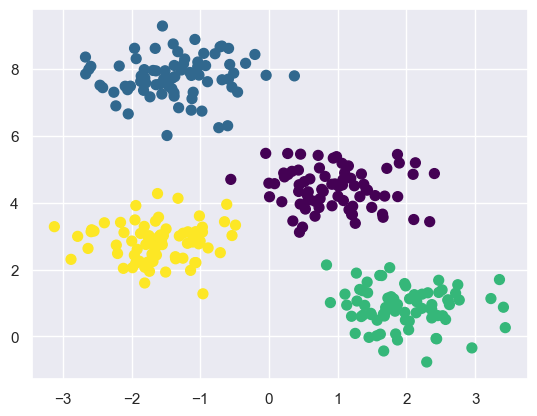

In [22]:
# We can write the EM algorithm with just a few lines of code

from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]  # initialise cluster centres
    centers = X[i]
    
    while True:
        # 2a. Assign labels based on closest center
        labels = pairwise_distances_argmin(X, centers)
        
        # 2b. Find new centers from means of points
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])
        
        # 2c. Check for convergence
        if np.all(centers == new_centers):
            break
        centers = new_centers
    
    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,
            s=50, cmap='viridis');

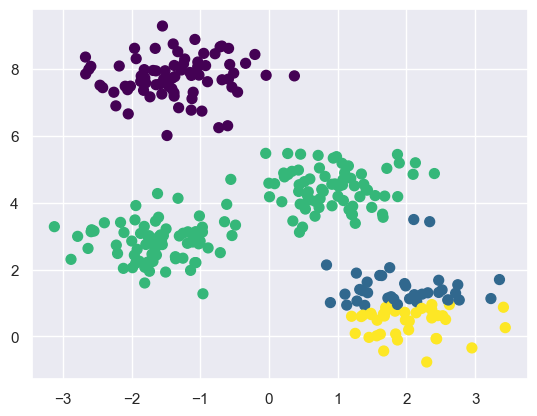

In [23]:
# But EM has some limitations...
# 1. What happens if we change the initial clusters?

centers, labels = find_clusters(X, 4, rseed=0)  # different seed
plt.scatter(X[:,0], X[:,1], c=labels,
            s=50, cmap='viridis');

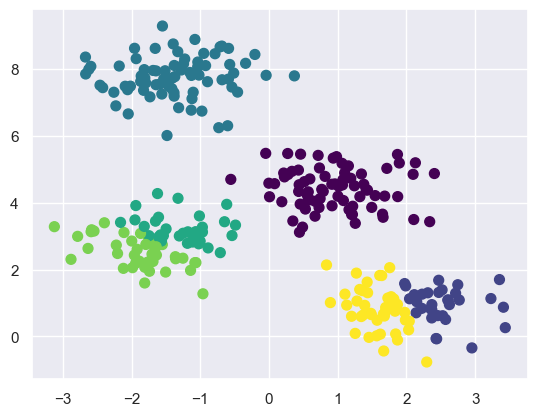

In [25]:
# 2. Must choose number of clusters in advance

labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:,0], X[:,1], c=labels,
            s=50, cmap='viridis');

In [26]:
# in practice:
# use a more sophisticated algorithm, e.g., Gaussian mixture models, DBSCAN
# or use some error function to find an optimum

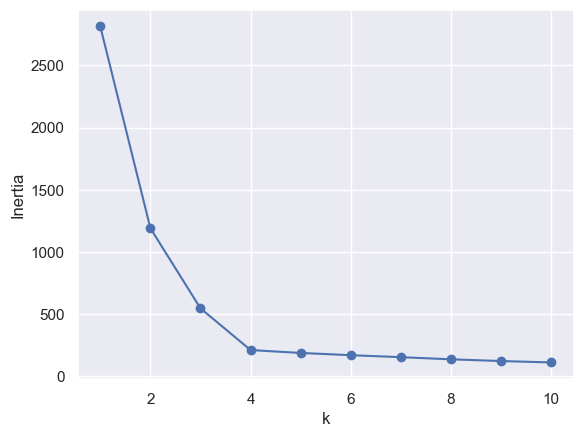

In [27]:
# Additional - Elbow method for optimal value of k

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia = []
K = range(1, 11)
for k in K:
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(K, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.show()

In [28]:
# 3. k-Means is limited to linear boundaries

from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

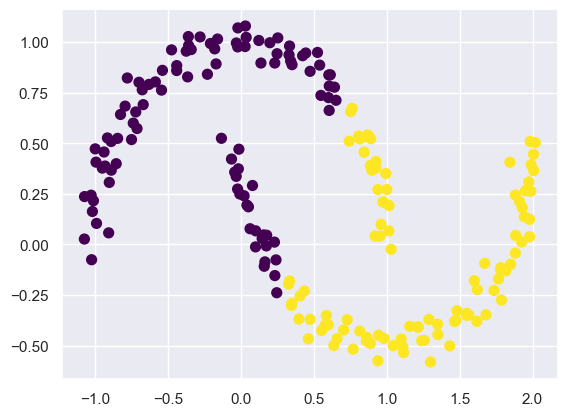

In [29]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:,0], X[:,1], c=labels,
            s=50, cmap='viridis');

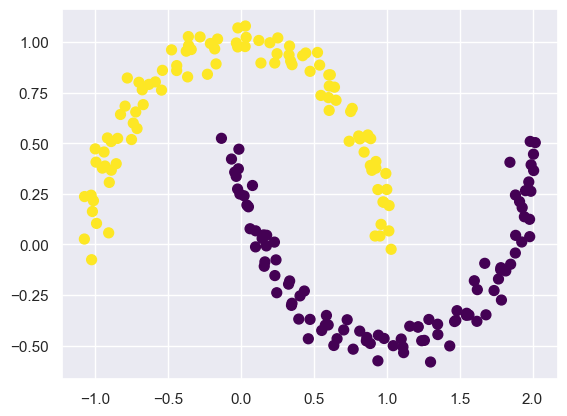

In [30]:
# Could we use a kernel transformation...?

from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, 
                           affinity='nearest_neighbors',
                           n_neighbors=15,  # default is 10, try higher values if user warning
                           assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:,0], X[:,1], c=labels,
            s=50, cmap='viridis');

In [ ]:
# 4. k-Means can be slow for large samples
# use batch-based k-Means

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> References & Notes </h2>
</div>

**References**

- VanderPlas, J. (2016). *Python data science handbook: Essential tools for working with data*. O’Reilly Media. https://jakevdp.github.io/PythonDataScienceHandbook/

**Notes**

-   Excerpts from Python Data Science Handbook by Jake VanderPlas are used. The text is released under the CC-BY-NC-ND license, and the code examples are released under the MIT license.